# 横磁場イジングモデル

## 横磁場イジングモデルとは

ある一つの方向のイジング相互作用に対して、それと垂直な向きの磁場を組み合わせたもの。

今回は以下のモデルを考える。

\begin{equation}
H = -J\sum_i{Z_i Z_{i+1}} -h\sum_i{X_i}
\end{equation}

- **第1項について**

    この項は隣り合うスピンを揃えようとする相互作用を表しています。

    実際に計算すると
    
    \begin{equation}
    \begin{aligned}
    Z_1 Z_0\ket{00} &= +1\ket{00} \\
    Z_1 Z_0\ket{11} &= +1\ket{11} \\
    Z_1 Z_0\ket{01} &= -1\ket{00} \\
    Z_1 Z_0\ket{10} &= -1\ket{11} \\
    \end{aligned}
    \end{equation}

    これから隣同士のスピンが揃っているとエネルギーが小さくなり、揃っていないとエネルギーが大きくなる。すなわちスピンが揃っている方が好まれるモデルになっている。

- **第2項について**

    スピンをZの軸からXの軸へ傾けるような量子揺らぎを表しています。


## 今回のゴール

$H$の基底エネルギー$E_0$と初期状態$\ket{+\cdots+}$からクエンチ後の横磁化$m_x(t)$の時間発展を求める。

## 今回行う解き方
1.  **厳密対角化**

    $2^n\times2^n$行列を対角化する。

1.  **Jordan-Wigner変換を用いてフェルミオンの問題に置き換える方法**

    フェルミオンの問題に置き換えて考えることで厳密に解くことができる。
    大まかな流れは

1.  **Trotter分解を用いて量子回路で解く方法**

    量子回路を用いて解くことができるが、誤差の逆数のオーダーのゲート数が必要。

## 1.厳密対角化の一般論

### 1-1 基底エネルギー$E_0$

$H$を対角化し、その固有値の最小値が基底エネルギー$E_0$である。

### 1-2 横磁化$m_x(t)$

$m_x(t)$は以下のように計算できる。

\begin{equation}
m_x(t) = \bra{\psi(t)}M_x\ket{\psi(t)}, M_x = \sum_{j=1}^{n}{X_j}
\end{equation}

$X_j$はそれぞれのサイトのx成分を測る演算子であり、jサイト目が
- $\ket{+}$のとき$+1$
- $\ket{-}$のとき$-1$

になるもの。$M_x$はそれの平均であると考えるとわかりやすい。

以下で$\psi(t)$を求める。シュレンディンガー方程式より

\begin{equation}
i\frac{d}{dt}\ket{\psi(t)} = H\ket{\psi(t)} \Rightarrow \ket{\psi(t)} = e^{-iHt}\ket{\psi_9}
\end{equation}

ここで初期状態$\psi_0$を固有基底で展開する。

\begin{equation}
\psi_0 = \sum_n c_n\ket{n}, c_n = \bra{n}\ket{\psi_0}
\end{equation}

これを先ほどの式に代入すると

\begin{equation}
\begin{aligned}
\ket{\psi(t)} 
&= e^{-iHt}\ket{\psi_9} \\
&= \sum_n e^{-iHt}c_n\ket{n} \\
&= \sum_n e^{-iE_{n}t}c_n\ket{n} (\because H\ket{n}=E_n\ket{n})\\
\end{aligned}
\end{equation}

このように固有状態の時間発展が追いやすいことを用いる。

これらより横磁化$m_x(t)$は

\begin{equation}
\begin{aligned}
m_x(t)
&= \bra{\psi(t)}M_x\ket{\psi(t)} \\
&= \sum_{m, n} c_m^{*}c_n e^{i(E_m - E_n)t}\bra{m}M_x\ket{n}
\end{aligned}
\end{equation}

である。

### 1-3 具体例を考えてみる

$n=2, J=1, h=0.5$のときの基底エネルギー$E_0$、横磁化$m_x(t)$を計算してみる。

### 1-4 コードで確かめる

基底エネルギー E0 = -1.414214


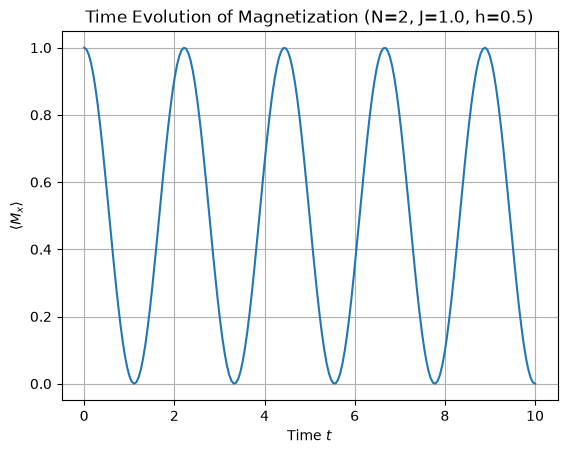

In [7]:
import numpy as np
from functools import reduce

# 基本的な演算子
I = np.eye(2, dtype=complex) #Iゲート
X = np.array([[0, 1], [1, 0]], dtype=complex) #Xゲート
Z = np.array([[1, 0], [0, -1]], dtype=complex) #Zゲート
def site_op(op, i, n):
    """i番目のサイトだけにopが作用する2^n次元の行列、すなわちI⊗I⊗...⊗op⊗...⊗Iを返す。"""
    if i < 0 or i >= n:
        raise ValueError("i must be in the range [0, n-1]")
    op_list = [I] * n
    op_list[i] = op
    return reduce(np.kron, op_list)

# ハミルトニアン
def hamiltonian(n, J, h, pbc=True):
    """1次元横磁場イジングモデル H = -J Σ Z_i Z_{i+1} - h Σ X_i を返す。
    pbc=True: 周期境界条件（Z_{n-1} Z_0 のボンドも含む）, pbc=False: 開放境界条件"""
    dim = 2**n
    H = np.zeros((dim, dim), dtype=complex)
    n_bonds = n if pbc else n - 1
    for i in range(n_bonds):
        H -= J * site_op(Z, i, n) @ site_op(Z, (i + 1) % n, n)  # 隣接スピン間の相互作用
    for i in range(n):
        H -= h * site_op(X, i, n)  # 横磁場
    return H

# 磁化
def magnetization_x(n):
    """M_x = (1/N) Σ X_j"""
    return sum(site_op(X, j, n) for j in range(n)) / n

# 基底エネルギーE0と基底状態ベクトル
def ground_state(H):
    w, v = np.linalg.eigh(H)
    return w[0], v[:, 0]

# 今回の初期状態|+ + ... +> = H^{⊗N}|00...0>：全成分が 1/sqrt(2^N)
def plus_state(n):
    return np.ones(2**n, dtype=complex) / np.sqrt(2**n)

# 時間発展した状態の期待値を計算する関数
def time_evolve_expectation(H, psi0, A, ts):
    """<ψ(t)|A|ψ(t)> を各時刻で計算する。
    1. H = U D U† と対角化（1回だけ）
    2. c = U† ψ0（固有基底で展開）
    3. ψ(t) = U e^{-iDt} c（位相を付けて戻す）
    4. 期待値 <ψ(t)|A|ψ(t)>
    """
    w, v = np.linalg.eigh(H)
    c = v.conj().T @ psi0
    out = []
    for t in ts:
        psi_t = v @ (np.exp(-1j * w * t) * c)
        out.append(np.real(psi_t.conj() @ A @ psi_t))
    return np.array(out)

import numpy as np
import matplotlib.pyplot as plt

import numpy as np
import matplotlib.pyplot as plt

# 例: N=2, J=1, h=0.5 の場合の基底状態と時間発展
N = 2
J = 1.0
h = 0.5
H = hamiltonian(N, J, h, pbc=False)   # N=2 は開放境界（周期境界だとボンドを2回数える）

# 基底エネルギーE_0
E0, psi_g = ground_state(H)

print(f"基底エネルギー E0 = {E0:.6f}")

# m_x(t)
psi0 = plus_state(N)
A = magnetization_x(N)
ts = np.linspace(0, 10, 200)
expectations = time_evolve_expectation(H, psi0, A, ts)

# グラフ
plt.plot(ts, expectations)
plt.xlabel("Time $t$")
plt.ylabel(r"$\langle M_x \rangle$")
plt.title(f"Time Evolution of Magnetization (N={N}, J={J}, h={h})")
plt.grid()
plt.show()

## 2. Jordan-Wigner変換を用いてフェルミオンの問題に置き換える方法

## 3. Trotter分解を用いて量子回路で解く方法